In [16]:
import pandas as pd

df = pd.read_csv("data/customer_churn.csv")

print("Dataset shape:", df.shape)
print(df.head())
print(df.info())
print(df["Churn"].value_counts())

Dataset shape: (7043, 21)
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingM

In [17]:
# Check missing values
print(df.isnull().sum())

# Check duplicate rows
print("Duplicates:", df.duplicated().sum())

# Check column types
print(df.dtypes)

# Basic statistics
df.describe(include="all")

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Duplicates: 0
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
Monthly

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


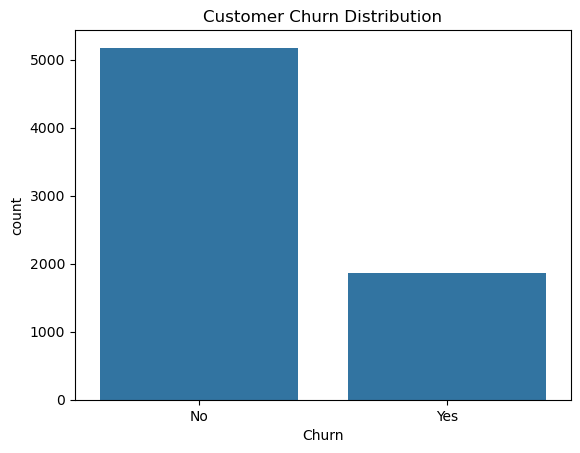

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

# Churn distribution
print(df["Churn"].value_counts(normalize=True) * 100)

sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.show()

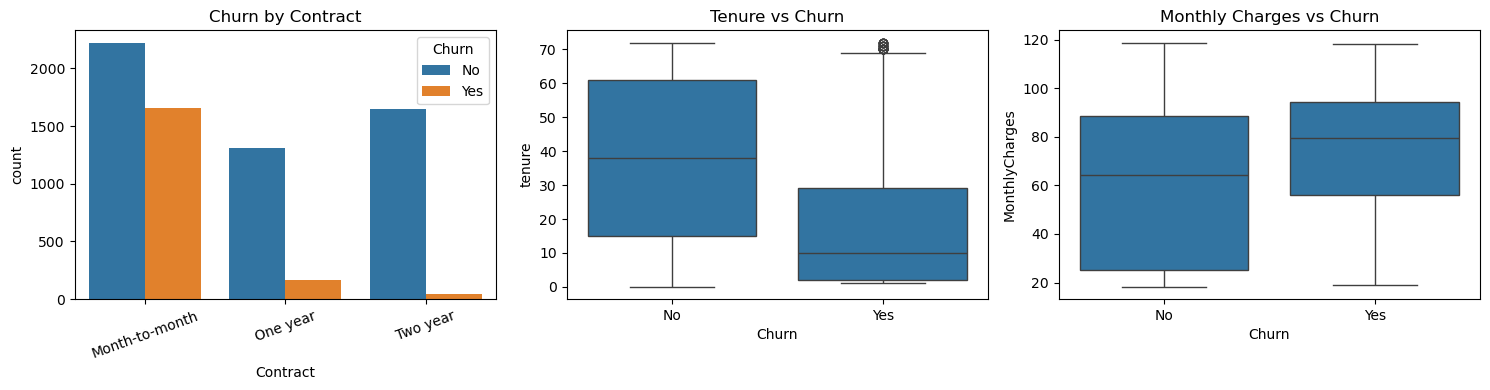

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(data=df, x="Contract", hue="Churn", ax=axes[0])
axes[0].set_title("Churn by Contract")
axes[0].tick_params(axis="x", rotation=20)

sns.boxplot(data=df, x="Churn", y="tenure", ax=axes[1])
axes[1].set_title("Tenure vs Churn")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=axes[2])
axes[2].set_title("Monthly Charges vs Churn")

plt.tight_layout()
plt.show()

In [20]:
# Convert TotalCharges to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)

# Check missing values after conversion
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

# Remove customerID because it is only an identifier
df = df.drop(columns=["customerID"])

# Remove rows with missing TotalCharges
df = df.dropna(subset=["TotalCharges"])

print("Cleaned dataset shape:", df.shape)
print(df.dtypes)

Missing TotalCharges: 11
Cleaned dataset shape: (7032, 20)
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


Churn              No    Yes
Contract                    
Month-to-month  57.29  42.71
One year        88.72  11.28
Two year        97.15   2.85


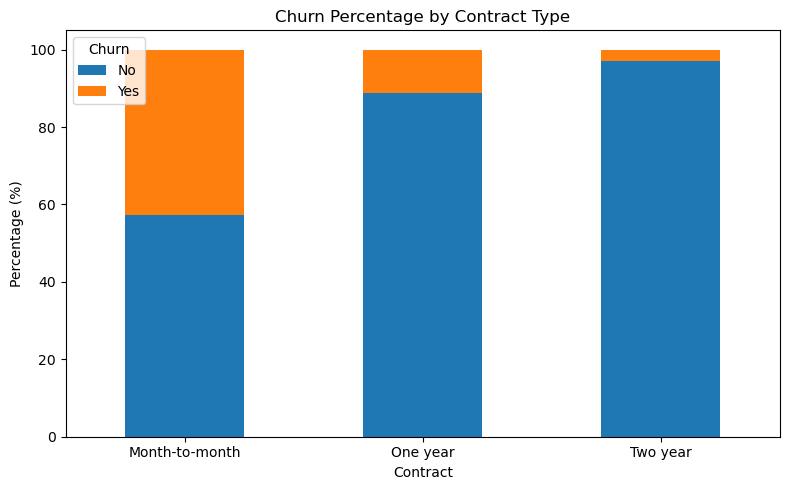

In [21]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

print(contract_churn.round(2))

contract_churn.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Churn Percentage by Contract Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [22]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Separate features and target
X = df.drop(columns=["Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

# Identify categorical and numerical columns
cat_cols = X.select_dtypes(include="object").columns
num_cols = X.select_dtypes(exclude="object").columns

# Preprocessing
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols)
])

# Split the data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Build and train the model
model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

# Evaluate
y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print(classification_report(
    y_test, y_pred,
    target_names=["No Churn", "Churn"]
))

Accuracy: 80.38 %
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1033
       Churn       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



In [23]:
import joblib

joblib.dump(model, "model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print("Random Forest Results")
print("---------------------")
print("Accuracy:", round(accuracy_score(y_test, rf_pred) * 100, 2), "%")
print("Precision:", round(precision_score(y_test, rf_pred), 3))
print("Recall:", round(recall_score(y_test, rf_pred), 3))
print("F1-score:", round(f1_score(y_test, rf_pred), 3))

Random Forest Results
---------------------
Accuracy: 78.54 %
Precision: 0.623
Recall: 0.487
F1-score: 0.547


In [25]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_prob = model.predict_proba(X_test)[:, 1]

for threshold in [0.3, 0.4, 0.5, 0.6]:
    y_pred_threshold = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision_score(y_test, y_pred_threshold), 3))
    print("Recall:", round(recall_score(y_test, y_pred_threshold), 3))
    print("F1-score:", round(f1_score(y_test, y_pred_threshold), 3))


Threshold: 0.3
Precision: 0.511
Recall: 0.759
F1-score: 0.611

Threshold: 0.4
Precision: 0.579
Recall: 0.684
F1-score: 0.627

Threshold: 0.5
Precision: 0.648
Recall: 0.572
F1-score: 0.608

Threshold: 0.6
Precision: 0.679
Recall: 0.385
F1-score: 0.491


In [26]:
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    GradientBoostingClassifier
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, recall_score, f1_score
import pandas as pd

# Dense encoding is needed for HistGradientBoosting
preprocessor_dense = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ("num", StandardScaler(), num_cols)
])

models = {
    "Logistic Regression": model,
    "Random Forest": Pipeline([
        ("prep", preprocessor),
        ("clf", RandomForestClassifier(
            n_estimators=300, random_state=42, n_jobs=-1
        ))
    ]),
    "Extra Trees": Pipeline([
        ("prep", preprocessor),
        ("clf", ExtraTreesClassifier(
            n_estimators=300, random_state=42, n_jobs=-1
        ))
    ]),
    "Gradient Boosting": Pipeline([
        ("prep", preprocessor_dense),
        ("clf", GradientBoostingClassifier(random_state=42))
    ]),
    "Hist Gradient Boosting": Pipeline([
        ("prep", preprocessor_dense),
        ("clf", HistGradientBoostingClassifier(
            max_iter=150, random_state=42
        ))
    ])
}

results = []

for name, clf in models.items():
    if name != "Logistic Regression":
        clf.fit(X_train, y_train)

    pred = clf.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test, pred) * 100, 2),
        "Churn Recall (%)": round(recall_score(y_test, pred) * 100, 2),
        "Churn F1": round(f1_score(y_test, pred), 3)
    })

results_df = pd.DataFrame(results)
print(results_df.sort_values("Accuracy (%)", ascending=False).to_string(index=False))

                 Model  Accuracy (%)  Churn Recall (%)  Churn F1
   Logistic Regression         80.38             57.22     0.608
     Gradient Boosting         79.60             52.94     0.580
         Random Forest         78.82             49.20     0.553
Hist Gradient Boosting         77.61             52.41     0.554
           Extra Trees         75.69             47.33     0.509


In [27]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

param_grid = {
    "classifier__C": [0.01, 0.1, 0.5, 1, 2, 5, 10],
    "classifier__class_weight": [None, "balanced"],
    "classifier__solver": ["lbfgs"]
}

grid = GridSearchCV(
    pipe,
    param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring="accuracy",
    n_jobs=-1
)

grid.fit(X_train, y_train)

best_model = grid.best_estimator_
pred = best_model.predict(X_test)

from sklearn.metrics import accuracy_score, classification_report

print("Best parameters:", grid.best_params_)
print("Cross-validation accuracy:", round(grid.best_score_ * 100, 2), "%")
print("Test accuracy:", round(accuracy_score(y_test, pred) * 100, 2), "%")
print(classification_report(y_test, pred))

Best parameters: {'classifier__C': 0.01, 'classifier__class_weight': None, 'classifier__solver': 'lbfgs'}
Cross-validation accuracy: 80.37 %
Test accuracy: 79.74 %
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1033
           1       0.65      0.51      0.57       374

    accuracy                           0.80      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.79      0.80      0.79      1407



In [30]:
!pip install xgboost
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

xgb_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=2,
        eval_metric="logloss",
        random_state=42
    ))
])

xgb_model.fit(X_train, y_train)

xgb_pred = xgb_model.predict(X_test)

print("XGBoost Accuracy:",
      round(accuracy_score(y_test, xgb_pred) * 100, 2), "%")
print(classification_report(y_test, xgb_pred))

  Using cached xgboost-3.4.1-py3-none-macosx_12_0_arm64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-macosx_12_0_arm64.whl (2.4 MB)
XGBoost Accuracy: 79.6 %
              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1033
           1       0.64      0.53      0.58       374

    accuracy                           0.80      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.79      0.80      0.79      1407



In [31]:
# Create a fresh copy of the cleaned data
df_fe = df.copy()

# Feature engineering
df_fe["AvgMonthlySpend"] = (
    df_fe["TotalCharges"] / df_fe["tenure"].replace(0, 1)
)

df_fe["HasInternet"] = (
    df_fe["InternetService"] != "No"
).astype(int)

df_fe["NumServices"] = (
    (df_fe["PhoneService"] == "Yes").astype(int)
    + (df_fe["InternetService"] != "No").astype(int)
    + (df_fe["OnlineSecurity"] == "Yes").astype(int)
    + (df_fe["OnlineBackup"] == "Yes").astype(int)
    + (df_fe["DeviceProtection"] == "Yes").astype(int)
    + (df_fe["TechSupport"] == "Yes").astype(int)
    + (df_fe["StreamingTV"] == "Yes").astype(int)
    + (df_fe["StreamingMovies"] == "Yes").astype(int)
)

# Separate features and target
X_fe = df_fe.drop(columns=["Churn"])
y_fe = df_fe["Churn"].map({"No": 0, "Yes": 1})

# Rebuild column lists and preprocessing
cat_fe = X_fe.select_dtypes(include="object").columns
num_fe = X_fe.select_dtypes(exclude="object").columns

preprocessor_fe = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_fe),
    ("num", StandardScaler(), num_fe)
])

X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe, y_fe, test_size=0.2, random_state=42, stratify=y_fe
)

model_fe = Pipeline([
    ("preprocessor", preprocessor_fe),
    ("classifier", LogisticRegression(C=0.01, max_iter=2000))
])

model_fe.fit(X_train_fe, y_train_fe)
pred_fe = model_fe.predict(X_test_fe)

print("Feature-engineered accuracy:",
      round(accuracy_score(y_test_fe, pred_fe) * 100, 2), "%")
print(classification_report(y_test_fe, pred_fe))

Feature-engineered accuracy: 79.53 %
              precision    recall  f1-score   support

           0       0.83      0.90      0.87      1033
           1       0.65      0.51      0.57       374

    accuracy                           0.80      1407
   macro avg       0.74      0.70      0.72      1407
weighted avg       0.78      0.80      0.79      1407



In [32]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.8/28.8 MB 7.1 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [catboost]1/2 [catboost]


In [33]:
from catboost import CatBoostClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split

X_cat = df.drop(columns=["Churn"]).copy()
y_cat = df["Churn"].map({"No": 0, "Yes": 1})

# Identify categorical columns
cat_features = X_cat.select_dtypes(include="object").columns.tolist()

# CatBoost handles categorical features directly
for col in cat_features:
    X_cat[col] = X_cat[col].fillna("Unknown").astype(str)

X_train_cat, X_test_cat, y_train_cat, y_test_cat = train_test_split(
    X_cat, y_cat,
    test_size=0.2,
    random_state=42,
    stratify=y_cat
)

cat_model = CatBoostClassifier(
    iterations=800,
    depth=5,
    learning_rate=0.03,
    loss_function="Logloss",
    verbose=False,
    random_seed=42
)

cat_model.fit(X_train_cat, y_train_cat, cat_features=cat_features)

cat_pred = cat_model.predict(X_test_cat).ravel()

print("CatBoost Accuracy:",
      round(accuracy_score(y_test_cat, cat_pred) * 100, 2), "%")
print(classification_report(y_test_cat, cat_pred))

CatBoost Accuracy: 78.96 %
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1033
           1       0.64      0.49      0.55       374

    accuracy                           0.79      1407
   macro avg       0.73      0.69      0.71      1407
weighted avg       0.78      0.79      0.78      1407



In [34]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

xgb_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        eval_metric="logloss",
        random_state=42
    ))
])

params = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [2, 3, 4],
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__min_child_weight": [1, 5],
    "classifier__subsample": [0.8],
    "classifier__colsample_bytree": [0.8]
}

search = GridSearchCV(
    xgb_pipe,
    params,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best CV accuracy:", round(search.best_score_ * 100, 2), "%")

best_xgb = search.best_estimator_
pred = best_xgb.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, pred) * 100, 2), "%")
print(classification_report(y_test, pred))

Fitting 3 folds for each of 54 candidates, totalling 162 fits
Best parameters: {'classifier__colsample_bytree': 0.8, 'classifier__learning_rate': 0.03, 'classifier__max_depth': 2, 'classifier__min_child_weight': 5, 'classifier__n_estimators': 200, 'classifier__subsample': 0.8}
Best CV accuracy: 80.52 %
Test accuracy: 79.6 %
              precision    recall  f1-score   support

           0       0.83      0.90      0.87      1033
           1       0.65      0.51      0.57       374

    accuracy                           0.80      1407
   macro avg       0.74      0.70      0.72      1407
weighted avg       0.79      0.80      0.79      1407



                                Feature  Importance
32         cat__Contract_Month-to-month    0.350860
23                  cat__TechSupport_No    0.100354
14               cat__OnlineSecurity_No    0.096173
12     cat__InternetService_Fiber optic    0.078436
39  cat__PaymentMethod_Electronic check    0.062964
42                          num__tenure    0.037233
34               cat__Contract_Two year    0.035306
35             cat__PaperlessBilling_No    0.022828
17                 cat__OnlineBackup_No    0.022814
28                 cat__StreamingTV_Yes    0.020948
31             cat__StreamingMovies_Yes    0.018790
33               cat__Contract_One year    0.018670
11             cat__InternetService_DSL    0.017363
43                  num__MonthlyCharges    0.015609
36            cat__PaperlessBilling_Yes    0.014529


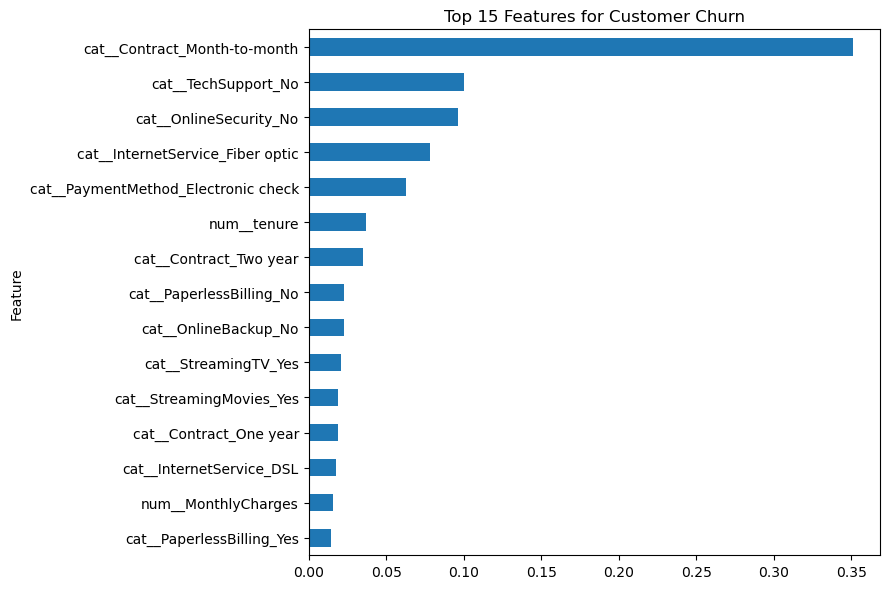

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

# Get feature names after preprocessing
feature_names = best_xgb.named_steps["preprocessor"].get_feature_names_out()
importances = best_xgb.named_steps["classifier"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

print(importance_df.head(15))

importance_df.head(15).sort_values("Importance").plot(
    x="Feature",
    y="Importance",
    kind="barh",
    legend=False,
    figsize=(9, 6)
)

plt.title("Top 15 Features for Customer Churn")
plt.tight_layout()
plt.show()

In [38]:
pip install lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 6.5 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [39]:
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

X = df.drop(columns=["Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

cat_cols = X.select_dtypes(include="object").columns
num_cols = X.select_dtypes(exclude="object").columns

prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", "passthrough", num_cols)
])

lgbm = Pipeline([
    ("prep", prep),
    ("model", LGBMClassifier(
        objective="binary",
        n_estimators=500,
        learning_rate=0.02,
        num_leaves=15,
        max_depth=5,
        min_child_samples=30,
        reg_lambda=2,
        verbosity=-1,
        random_state=42
    ))
])

lgbm.fit(X_train, y_train)
pred = lgbm.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, pred) * 100, 2), "%")
print(classification_report(y_test, pred))

Accuracy: 80.03 %
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.64      0.56      0.60       374

    accuracy                           0.80      1407
   macro avg       0.75      0.72      0.73      1407
weighted avg       0.79      0.80      0.80      1407



In [42]:
from catboost import CatBoostClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, classification_report

# Categorical columns
cat_cols = X_train.select_dtypes(include="object").columns.tolist()
cat_indices = [X_train.columns.get_loc(c) for c in cat_cols]

X_train_cb = X_train.copy()
X_test_cb = X_test.copy()

for col in cat_cols:
    X_train_cb[col] = X_train_cb[col].fillna("Unknown").astype(str)
    X_test_cb[col] = X_test_cb[col].fillna("Unknown").astype(str)

cb = CatBoostClassifier(
    loss_function="Logloss",
    verbose=0,
    random_seed=42,
    thread_count=-1
)

params = {
    "iterations": [300, 600],
    "depth": [4, 6, 8],
    "learning_rate": [0.03, 0.05],
    "l2_leaf_reg": [3, 5]
}

search = GridSearchCV(
    cb,
    params,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    n_jobs=1,
    verbose=1
)

search.fit(
    X_train_cb,
    y_train,
    cat_features=cat_indices
)

best_cb = search.best_estimator_
pred = best_cb.predict(X_test_cb).ravel()

print("Best parameters:", search.best_params_)
print("CV accuracy:", round(search.best_score_ * 100, 2), "%")
print("Test accuracy:", round(accuracy_score(y_test, pred) * 100, 2), "%")
print(classification_report(y_test, pred))

Fitting 3 folds for each of 24 candidates, totalling 72 fits


Exception ignored in: <function ResourceTracker.__del__ at 0x108702480>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 84, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 93, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 118, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x104872480>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 84, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 93, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 118, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x10503a480>
Traceback (most recent call last

Best parameters: {'depth': 4, 'iterations': 300, 'l2_leaf_reg': 3, 'learning_rate': 0.03}
CV accuracy: 80.52 %
Test accuracy: 79.89 %
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1033
           1       0.65      0.52      0.58       374

    accuracy                           0.80      1407
   macro avg       0.75      0.71      0.72      1407
weighted avg       0.79      0.80      0.79      1407



In [43]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
import numpy as np

# Baseline: always predict the majority class
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)

print(
    "Majority-class accuracy:",
    round(dummy.score(X_test, y_test) * 100, 2), "%"
)

# Cross-validation for Logistic Regression
lr = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(C=1, max_iter=2000))
])

scores = cross_val_score(
    lr,
    X_train,
    y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring="accuracy",
    n_jobs=-1
)

print("CV scores:", np.round(scores * 100, 2))
print("Mean CV accuracy:", round(scores.mean() * 100, 2), "%")
print("CV standard deviation:", round(scores.std() * 100, 2), "%")


Majority-class accuracy: 73.42 %
CV scores: [81.16 79.02 78.93 80.27 81.87]
Mean CV accuracy: 80.25 %
CV standard deviation: 1.16 %


In [44]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.base import clone

# Create a validation set from training data
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=123,
    stratify=y_train
)

# Train Logistic Regression on the reduced training set
candidate = clone(model)
candidate.fit(X_fit, y_fit)

# Find threshold with highest validation accuracy
val_probs = candidate.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.20, 0.81, 0.01)
scores = [
    accuracy_score(y_val, (val_probs >= t).astype(int))
    for t in thresholds
]

best_threshold = thresholds[np.argmax(scores)]

print("Best threshold:", round(best_threshold, 2))
print("Validation accuracy:", round(max(scores) * 100, 2), "%")

# Evaluate once on the test set
test_probs = candidate.predict_proba(X_test)[:, 1]
test_pred = (test_probs >= best_threshold).astype(int)

print("Test accuracy:", round(
    accuracy_score(y_test, test_pred) * 100, 2
), "%")

Best threshold: 0.5
Validation accuracy: 80.8 %
Test accuracy: 80.03 %


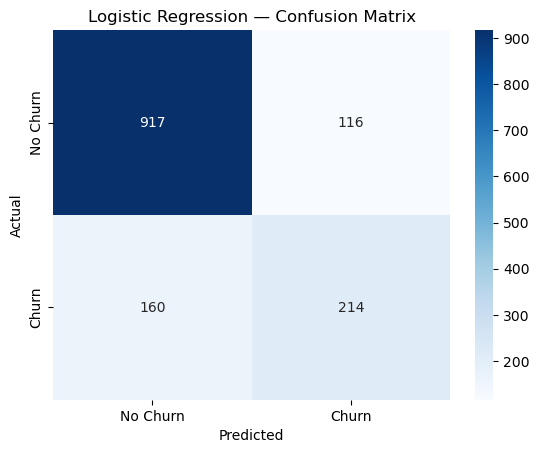

Misclassified customers: 276

Actual class of errors:
Actual
1    160
0    116
Name: count, dtype: int64

Contract distribution among errors:
Contract
Month-to-month    228
One year           40
Two year            8
Name: count, dtype: int64


In [45]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

pred = model.predict(X_test)

cm = confusion_matrix(y_test, pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression — Confusion Matrix")
plt.show()

errors = X_test.copy()
errors["Actual"] = y_test
errors["Predicted"] = pred
errors = errors[errors["Actual"] != errors["Predicted"]]

print("Misclassified customers:", len(errors))
print("\nActual class of errors:")
print(errors["Actual"].value_counts())
print("\nContract distribution among errors:")
print(errors["Contract"].value_counts())

In [46]:
print(pd.crosstab(
    errors["Contract"],
    [errors["Actual"], errors["Predicted"]],
    margins=True
))

Actual            0    1  All
Predicted         1    0     
Contract                     
Month-to-month  116  112  228
One year          0   40   40
Two year          0    8    8
All             116  160  276


In [47]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report

xgb_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", XGBClassifier(
        eval_metric="logloss",
        random_state=42,
        n_jobs=1
    ))
])

params = {
    "classifier__n_estimators": [100, 200, 300, 500, 700],
    "classifier__max_depth": [2, 3, 4, 5, 6],
    "classifier__learning_rate": [0.01, 0.02, 0.03, 0.05, 0.1],
    "classifier__min_child_weight": [1, 3, 5, 7],
    "classifier__subsample": [0.7, 0.8, 0.9, 1.0],
    "classifier__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "classifier__reg_lambda": [1, 3, 5, 10]
}

search = RandomizedSearchCV(
    xgb_pipe,
    params,
    n_iter=40,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X_train, y_train)

best_xgb = search.best_estimator_
pred = best_xgb.predict(X_test)

print("Best parameters:", search.best_params_)
print("CV accuracy:", round(search.best_score_ * 100, 2), "%")
print("Test accuracy:", round(accuracy_score(y_test, pred) * 100, 2), "%")
print(classification_report(y_test, pred))

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best parameters: {'classifier__subsample': 0.9, 'classifier__reg_lambda': 10, 'classifier__n_estimators': 200, 'classifier__min_child_weight': 7, 'classifier__max_depth': 3, 'classifier__learning_rate': 0.05, 'classifier__colsample_bytree': 0.7}
CV accuracy: 80.78 %
Test accuracy: 79.67 %
              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1033
           1       0.64      0.53      0.58       374

    accuracy                           0.80      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.79      0.80      0.79      1407



In [48]:
# Analyze churn rates by tenure groups
df_analysis = df.copy()

df_analysis["TenureGroup"] = pd.cut(
    df_analysis["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0-6", "7-12", "13-24", "25-48", "49-72"]
)

print("Churn rate by tenure group (%):")
print(
    (pd.crosstab(
        df_analysis["TenureGroup"],
        df_analysis["Churn"],
        normalize="index"
    )["Yes"] * 100).round(2)
)

print("\nChurn rate by contract and tenure (%):")
print(
    (pd.crosstab(
        [df_analysis["Contract"], df_analysis["TenureGroup"]],
        df_analysis["Churn"],
        normalize="index"
    )["Yes"] * 100).round(2)
)

Churn rate by tenure group (%):
TenureGroup
0-6      53.33
7-12     35.89
13-24    28.71
25-48    20.39
49-72     9.51
Name: Yes, dtype: float64

Churn rate by contract and tenure (%):
Contract        TenureGroup
Month-to-month  0-6            55.20
                7-12           42.00
                13-24          37.72
                25-48          32.92
                49-72          26.02
One year        0-6            10.53
                7-12           10.59
                13-24           8.12
                25-48          10.62
                49-72          12.93
Two year        0-6             0.00
                7-12            0.00
                13-24           0.00
                25-48           2.19
                49-72           3.33
Name: Yes, dtype: float64


In [49]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Use the cleaned dataset
df_grouped = df.copy()

df_grouped["TenureGroup"] = pd.cut(
    df_grouped["tenure"],
    bins=[-1, 6, 12, 24, 48, 72],
    labels=["0-6", "7-12", "13-24", "25-48", "49-72"]
).astype(str)

X_new = df_grouped.drop(columns=["Churn"])
y_new = df_grouped["Churn"].map({"No": 0, "Yes": 1})

cat_new = X_new.select_dtypes(include="object").columns
num_new = X_new.select_dtypes(exclude="object").columns

prep_new = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_new),
    ("num", StandardScaler(), num_new)
])

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(
    X_new, y_new, test_size=0.2,
    random_state=42, stratify=y_new
)

grouped_model = Pipeline([
    ("prep", prep_new),
    ("clf", LogisticRegression(C=1, max_iter=2000))
])

grouped_model.fit(X_train_new, y_train_new)
pred_new = grouped_model.predict(X_test_new)

print("Accuracy:", round(accuracy_score(y_test_new, pred_new) * 100, 2), "%")
print(classification_report(y_test_new, pred_new))


Accuracy: 79.46 %
              precision    recall  f1-score   support

           0       0.84      0.89      0.86      1033
           1       0.64      0.53      0.58       374

    accuracy                           0.79      1407
   macro avg       0.74      0.71      0.72      1407
weighted avg       0.79      0.79      0.79      1407

